# 03 K-means: finding the natural groups

**Step 5:** prepare the RFM values, choose the number of clusters, and profile them.
**Step 6:** compare the clusters with the hand-made RFM tiers, and test whether they predict future spending.
**Step 7:** name the segments and propose a campaign for each.

In [1]:
import matplotlib.pyplot as plt

# One consistent, colour-blind-safe look for every chart in this project
BLUE, ORANGE, AQUA, YELLOW, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.titlelocation": "left", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 10,
    "legend.frameon": False, "lines.linewidth": 2,
    "axes.prop_cycle": plt.cycler(color=[BLUE, ORANGE, AQUA, YELLOW]),
})

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

rfm = pd.read_csv("../data/processed/rfm.csv", index_col="customer_id")
VARS = ["recency", "frequency", "monetary"]

## 1. Prepare the inputs: log, then scale

K-means groups customers by **distance**. Two problems with the raw values:

1. **Skew.** A few customers spent hundreds of thousands of pounds. On the raw scale they would dominate every distance and the clusters would mostly separate "the giants" from everyone else. `log1p` (log of 1 + x) compresses the long tail.
2. **Different units.** Recency is in days (0 to 738), frequency in orders (1 to ~400), monetary in pounds. Standardising (mean 0, standard deviation 1) gives each an equal vote.

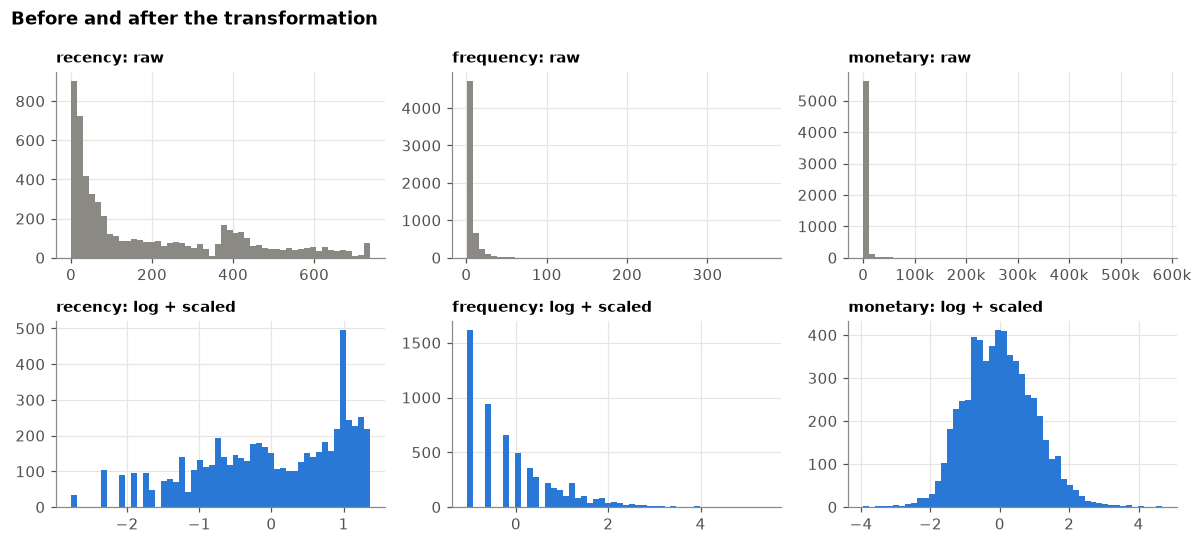

In [2]:
X = StandardScaler().fit_transform(np.log1p(rfm[VARS]))

fig, axes = plt.subplots(2, 3, figsize=(11, 5))
for i, col in enumerate(VARS):
    axes[0, i].hist(rfm[col], bins=50, color=GREY)
    axes[0, i].set_title(f"{col}: raw", fontsize=10)
    axes[0, i].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1000:.0f}k" if v >= 1000 else f"{v:.0f}"))
    axes[1, i].hist(X[:, i], bins=50, color=BLUE)
    axes[1, i].set_title(f"{col}: log + scaled", fontsize=10)
fig.suptitle("Before and after the transformation", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig("../figures/rfm_transform.png")
plt.show()

## 2. How many clusters?

K-means needs the number of clusters *k* in advance. Two standard checks for k = 2 to 10:

- **Elbow (inertia):** total distance from customers to their cluster centre. It always falls as k grows; look for where the improvement slows down.
- **Silhouette score:** for each customer, how much closer they are to their own cluster than to the next one, averaged (from -1 to 1; higher is better separated).

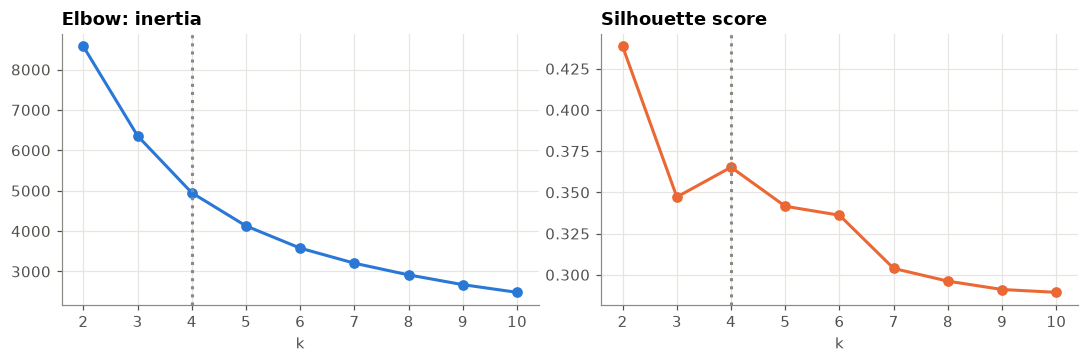

k,2,3,4,5,6,7,8,9,10
inertia,8573.000,6358.000,4948.000,4128.000,3578.000,3205.000,2916.000,2674.000,2483.000
silhouette,0.438,0.347,0.365,0.342,0.336,0.304,0.296,0.291,0.289


In [3]:
ks = range(2, 11)
inertia, silhouette = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    inertia.append(km.inertia_)
    silhouette.append(silhouette_score(X, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].plot(list(ks), inertia, marker="o", color=BLUE)
axes[0].set_title("Elbow: inertia")
axes[0].set_xlabel("k")
axes[1].plot(list(ks), silhouette, marker="o", color=ORANGE)
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("k")
for ax in axes:
    ax.axvline(4, color=GREY, linestyle=":")
fig.tight_layout()
fig.savefig("../figures/choosing_k.png")
plt.show()
pd.DataFrame({"k": list(ks), "inertia": np.round(inertia), "silhouette": np.round(silhouette, 3)}).set_index("k").T

**Choosing k = 4.**

- The silhouette score is highest at k = 2, but two segments ("good customers" and "the rest") would not give marketing anything new: the RFM tiers already say that.
- Among useful sizes, **k = 4 is a local peak**: better separated than 3 and than 5 or more.
- The elbow curve bends around 4 to 5: after that, extra clusters buy much less.
- Four segments is also a number a marketing team can actually run campaigns for.

Statistics narrows the choice; the business use makes it.

In [4]:
K_FINAL = 4
km = KMeans(n_clusters=K_FINAL, n_init=10, random_state=42).fit(X)
rfm["cluster"] = km.labels_
profile = rfm.groupby("cluster").agg(customers=("recency", "size"),
                                     recency_median=("recency", "median"), frequency_median=("frequency", "median"),
                                     monetary_median=("monetary", "median"), revenue=("monetary", "sum"))
profile["pct_of_customers"] = (profile.customers / profile.customers.sum() * 100).round(1)
profile["pct_of_revenue"] = (profile.revenue / profile.revenue.sum() * 100).round(1)
profile.round(1)

,customers,recency_median,frequency_median,monetary_median,revenue,pct_of_customers,pct_of_revenue
cluster,,,,,,,
0,1220,23.0,3.0,707.7,1002636.2,20.8,5.9
1,1110,15.0,13.0,5117.7,12217497.4,19.0,71.6
2,2054,398.0,1.0,291.4,697806.2,35.1,4.1
3,1468,157.0,5.0,1580.4,3150628.2,25.1,18.5


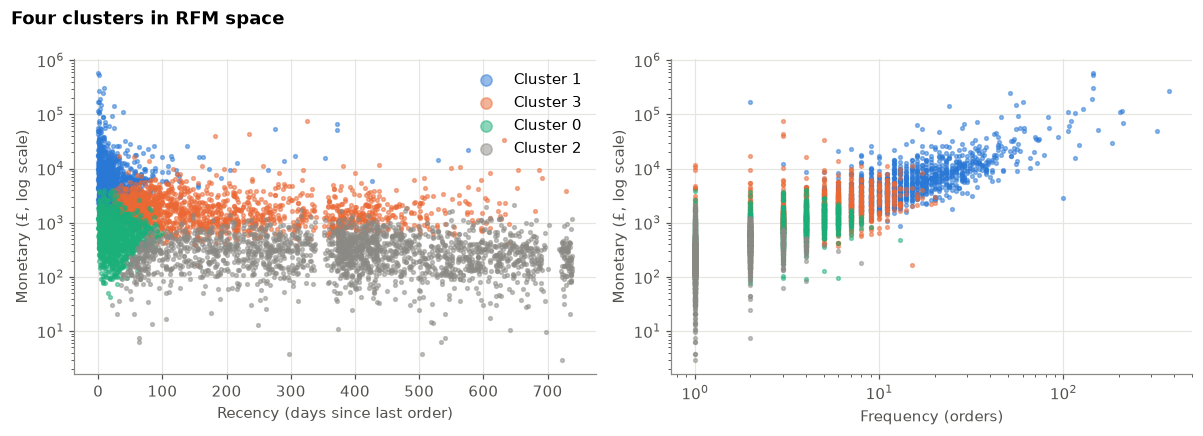

In [5]:
# Fixed colour per kind of cluster (the same colours are reused for the named segments in Step 7)
top = profile.monetary_median.idxmax()
lapsed = profile.recency_median.idxmax()
middle = profile.drop(index=[top, lapsed]).sort_values("recency_median").index
colour_of_cluster = {top: BLUE, middle[1]: ORANGE, middle[0]: AQUA, lapsed: GREY}

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for c in [top, middle[1], middle[0], lapsed]:
    part = rfm[rfm.cluster == c]
    axes[0].scatter(part.recency, part.monetary, s=6, alpha=0.5, color=colour_of_cluster[c], label=f"Cluster {c}")
    axes[1].scatter(part.frequency, part.monetary, s=6, alpha=0.5, color=colour_of_cluster[c], label=f"Cluster {c}")
for ax, xl in zip(axes, ["Recency (days since last order)", "Frequency (orders)"]):
    ax.set_yscale("log"); ax.set_xlabel(xl); ax.set_ylabel("Monetary (£, log scale)")
axes[1].set_xscale("log")
axes[0].legend(markerscale=3)
fig.suptitle("Four clusters in RFM space", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig("../figures/clusters_scatter.png")
plt.show()

---
# Step 6: Evaluate the clusters

## 3. Do the clusters agree with the hand-made RFM tiers?

In [6]:
agreement = pd.crosstab(rfm.cluster, rfm.tier, margins=True)
agreement[["Gold", "Silver", "Bronze", "All"]]

tier,Gold,Silver,Bronze,All
cluster,,,,
0,252,914,54,1220
1,1107,3,0,1110
2,0,349,1705,2054
3,352,1112,4,1468
All,1711,2378,1763,5852


In [7]:
pd.crosstab(rfm.cluster, rfm.tier, normalize="index").round(2)[["Gold", "Silver", "Bronze"]]

tier,Gold,Silver,Bronze
cluster,,,
0,0.21,0.75,0.04
1,1.00,0.00,0.00
2,0.00,0.17,0.83
3,0.24,0.76,0.00


**Where they agree:** the big-spending cluster is almost entirely Gold, and the long-gone one-time buyers are almost entirely Bronze. K-means rediscovered the obvious groups on its own, which is a good sign that the clusters are real.

**Where they disagree, and why it matters:** the two middle clusters are mostly **Silver**, the tier that RFM uses as a catch-all. One of them has bought recently but only a few times (new customers); the other bought often but has not been back for months (drifting regulars). Their RFM *totals* are similar, so the tiers lump them together, but they need opposite messages. This is exactly the split I hoped for in Step 4, and the main reason to use clustering here.

## 4. Do the segments mean anything for the future?

A segmentation is only useful if customers in different segments actually **behave** differently afterwards. Test: rebuild the whole pipeline using only data up to 9 June 2011, then measure how much each segment spent in the **following six months**, which the clustering never saw.

In [8]:
tx = pd.read_parquet("../data/processed/transactions_clean.parquet")
cutoff = pd.Timestamp("2011-06-10")
past, future = tx[tx.invoice_date < cutoff], tx[tx.invoice_date >= cutoff]

rfm_past = past.groupby("customer_id").agg(
    recency=("invoice_date", lambda d: (cutoff - d.max()).days),
    frequency=("invoice", "nunique"), monetary=("revenue", "sum"))
km_past = KMeans(n_clusters=K_FINAL, n_init=10, random_state=42).fit(
    StandardScaler().fit_transform(np.log1p(rfm_past[VARS])))
rfm_past["cluster"] = km_past.labels_

spend_next = future.groupby("customer_id").revenue.sum()
rfm_past["spend_next_6m"] = spend_next.reindex(rfm_past.index).fillna(0)
rfm_past["bought_again"] = rfm_past.spend_next_6m > 0
check = rfm_past.groupby("cluster").agg(customers=("recency", "size"), recency_median=("recency", "median"),
                                        frequency_median=("frequency", "median"), monetary_median=("monetary", "median"),
                                        bought_again=("bought_again", "mean"), avg_spend_next_6m=("spend_next_6m", "mean"))
check.sort_values("avg_spend_next_6m", ascending=False).round(2)

,customers,recency_median,frequency_median,monetary_median,bought_again,avg_spend_next_6m
cluster,,,,,,
1,722,20.0,13.0,5162.08,0.93,4074.99
3,633,17.0,3.0,865.60,0.70,552.77
2,1499,175.0,4.0,1380.44,0.57,528.99
0,2090,240.0,1.0,291.76,0.28,209.50


The segments found on old data separate future behaviour clearly: over the next six months, more than 9 in 10 customers in the top segment bought again and spent on average about 19 times as much as the lapsed segment, where fewer than 3 in 10 came back. The two middle segments spend similar amounts, but differ in how recently they bought, which is exactly why they need different messages. The segments are not just a description of the past; they **rank future value**, which is what marketing needs to decide where to spend.

---
# Step 7: Name the segments and decide what to say to each

In [9]:
# Name clusters from their profile, so names stay right even if K-means numbers them differently
p = profile.copy()
names = {}
names[p.monetary_median.idxmax()] = "Loyal big spenders"
names[p.recency_median.idxmax()] = "Lapsed one-time buyers"
rest = p.drop(index=list(names)).sort_values("recency_median")
names[rest.index[0]] = "New and promising"
names[rest.index[1]] = "Drifting regulars"
rfm["segment"] = rfm.cluster.map(names)

order = ["Loyal big spenders", "Drifting regulars", "New and promising", "Lapsed one-time buyers"]
segments = rfm.groupby("segment").agg(customers=("recency", "size"), recency_median=("recency", "median"),
                                      frequency_median=("frequency", "median"), monetary_median=("monetary", "median"),
                                      revenue=("monetary", "sum")).reindex(order)
segments["share_of_customers"] = (segments.customers / segments.customers.sum() * 100).round(1)
segments["share_of_revenue"] = (segments.revenue / segments.revenue.sum() * 100).round(1)
segments.round(0)

,customers,recency_median,frequency_median,monetary_median,revenue,share_of_customers,share_of_revenue
segment,,,,,,,
Loyal big spenders,1110,15.0,13.0,5118.0,12217497.0,19.0,72.0
Drifting regulars,1468,157.0,5.0,1580.0,3150628.0,25.0,18.0
New and promising,1220,23.0,3.0,708.0,1002636.0,21.0,6.0
Lapsed one-time buyers,2054,398.0,1.0,291.0,697806.0,35.0,4.0


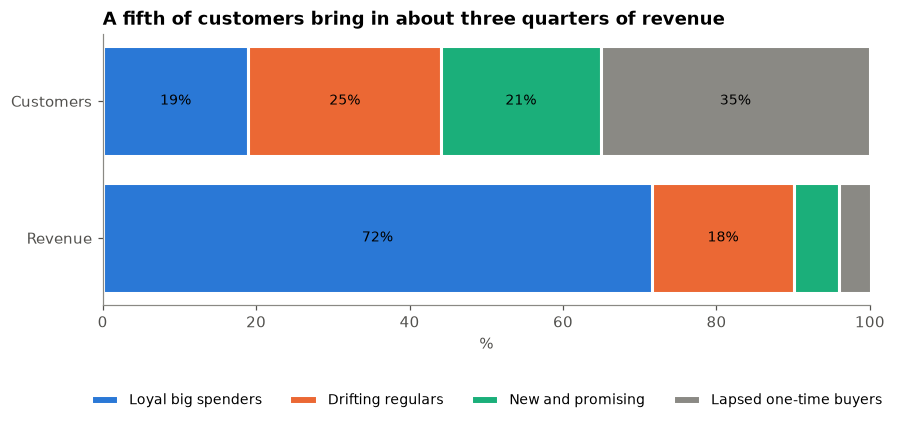

In [10]:
colour_of = dict(zip(order, [BLUE, ORANGE, AQUA, GREY]))
fig, ax = plt.subplots(figsize=(9, 3.2))
left_c = left_r = 0
for seg in order:
    c, r = segments.loc[seg, "share_of_customers"], segments.loc[seg, "share_of_revenue"]
    ax.barh(1, c, left=left_c, color=colour_of[seg], edgecolor="white", linewidth=2)
    ax.barh(0, r, left=left_r, color=colour_of[seg], edgecolor="white", linewidth=2, label=seg)
    if c > 6: ax.text(left_c + c / 2, 1, f"{c:.0f}%", ha="center", va="center", color="black", fontsize=9)
    if r > 6: ax.text(left_r + r / 2, 0, f"{r:.0f}%", ha="center", va="center", color="black", fontsize=9)
    left_c += c; left_r += r
ax.set_yticks([0, 1], ["Revenue", "Customers"])
ax.set_xlim(0, 100)
ax.set_xlabel("%")
ax.grid(False)
ax.set_title("A fifth of customers bring in about three quarters of revenue")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.28), fontsize=9)
fig.savefig("../figures/segments_share.png")
plt.show()

## Campaign per segment

| Segment | Who they are | Campaign |
|---|---|---|
| **Loyal big spenders** | Bought recently, often, and spend the most | **Protect and reward.** Early access to new collections, a named account contact, free delivery on bulk orders. Do not discount: they already buy at full price. |
| **Drifting regulars** | Used to order several times, but not for months | **Win back, now.** Personal "we miss you" email with their past favourite products and a time-limited offer. This is the segment most at risk of becoming lapsed, and still worth saving. |
| **New and promising** | Bought recently, but only a few orders so far and small baskets | **Grow the habit.** A welcome series with best-sellers and a small incentive on the next order. Moving them from a few orders to regular ordering is where loyalty is built. |
| **Lapsed one-time buyers** | One order, a year or more ago, low spend | **Low-cost reactivation only.** Include in the big seasonal campaign (October), no individual effort. Suppress from frequent emails to protect sender reputation. |

In [11]:
export = rfm[["recency", "frequency", "monetary", "R", "F", "M", "tier", "segment"]].round({"monetary": 2})
export.to_csv("../reports/segments.csv")
segments.round(1).to_csv("../reports/segment_summary.csv")
print(f"Saved reports/segments.csv ({len(export):,} customers) and reports/segment_summary.csv")

Saved reports/segments.csv (5,852 customers) and reports/segment_summary.csv
